# Single-Stock Risk Report

A parameterized report for one ticker over one date range, built from the cleaned table `ohlc_hw_cleaned` (created by `01_data_cleaning.ipynb`).

- **Run it by hand:** edit the parameters cell and choose *Restart & Run All*.
- **Run it in batch:** `03_run_all_stocks.py` executes this notebook with Papermill, which injects new parameter values right after the cell tagged `parameters`.

**Conventions**

- Returns, drawdown and total return use **adjusted close**, so splits and dividends do not look like losses.
- Volatility, Sharpe ratio and the daily statistics use daily **log returns** `log(P_t / P_{t-1})`.
- Annualization uses 252 trading days. The Sharpe ratio uses the course's approximation with a 2% annual risk-free rate.
- Values are kept as fractions in calculations (0.05 = 5%) and formatted as percentages only for display.

In [1]:
import json
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from IPython.display import display
import scrapbook as sb

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

TRADING_DAYS = 252
VOL_WINDOW = 20          # rolling volatility window (returns)
MA_WINDOW = 50           # moving-average window (prices)
RISK_FREE_RATE = 0.02    # annual, course convention

# One color scheme for every panel.
COLORS = {'up': '#2e7d32', 'down': '#c62828', 'warmup': '#9e9e9e', 'ma': '#1f3b73',
          'vol': '#6a1b9a', 'mean': '#212121', 'drawdown': '#c62828'}

## 1. Parameters

The next cell carries the Papermill **`parameters` cell tag** (check it under *Property Inspector → Cell Tags* in JupyterLab, or *View → Cell Toolbar → Tags* in classic Notebook). The `# Parameters` comment by itself is not enough.

`db_path` is relative to this homework folder, which is the working directory both in Jupyter and when the batch script runs the report.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Local working database written by 01_data_cleaning.ipynb

In [3]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "C:\\Users\\jyk71\\OneDrive\\Desktop\\Berkeley MFE Pre-Program Prep Materials\\MFE Python\\UCB-MFE-python-preprogram-2026-winter\\Homeworks\\HW2\\Ian_Kwon\\data\\data.db"


## 2. Data loading

`load_prices` validates the inputs before touching the data: the database must exist, the dates must parse and be in order, and the ticker must exist in `ohlc_hw_cleaned`. The date filter is inclusive. A report needs at least **21 prices**, because 20 returns (one full volatility window) require 21 prices.

In [4]:
def load_prices(db_path, ticker, start_date, end_date):
    """Load cleaned daily prices for one ticker between two dates (inclusive), indexed by date.

    Raises FileNotFoundError for a missing database and ValueError for bad dates, an unknown
    ticker or an empty result, so a batch run records a clear failure reason.
    """
    database = Path(db_path).expanduser().resolve()
    if not database.is_file():
        raise FileNotFoundError(f'{database} not found: run 01_data_cleaning.ipynb first.')
    start, end = pd.Timestamp(start_date), pd.Timestamp(end_date)
    if start > end:
        raise ValueError(f'start_date {start_date} is after end_date {end_date}.')
    query = """
        SELECT ts, open, high, low, close, adj_close, volume, any_repair
        FROM ohlc_hw_cleaned
        WHERE ticker = ? AND ts BETWEEN ? AND ?
        ORDER BY ts
    """
    with closing(sqlite3.connect(database.as_uri() + '?mode=ro', uri=True)) as conn:
        if conn.execute('SELECT 1 FROM ohlc_hw_cleaned WHERE ticker = ? LIMIT 1', (ticker,)).fetchone() is None:
            raise ValueError(f'Ticker {ticker!r} is not in ohlc_hw_cleaned.')
        prices = pd.read_sql_query(query, conn, params=(ticker, start.strftime('%Y-%m-%d'), end.strftime('%Y-%m-%d')),
                                   parse_dates=['ts'], index_col='ts')
    if prices.empty:
        raise ValueError(f'{ticker} has no observations between {start_date} and {end_date}.')
    return prices


ticker = str(ticker).strip().upper()
df = load_prices(db_path, ticker, start_date, end_date)
first_date, last_date = df.index.min(), df.index.max()
print(f'{ticker} from {start_date} to {end_date}: {len(df)} trading days')
print(f'Actual observations: {first_date.date()} to {last_date.date()}')
if last_date < pd.Timestamp(end_date) - pd.Timedelta(days=7):
    print(f'Note: {ticker} data ends on {last_date.date()}, before the requested end date. '
          'Metrics cover only the available history; nothing is extrapolated.')
if df['any_repair'].any():
    print(f'{int(df["any_repair"].sum())} of these rows contain values repaired during cleaning (see repair flags).')
MIN_PRICES = VOL_WINDOW + 1
if len(df) < MIN_PRICES:
    raise ValueError(f'{ticker}: {len(df)} prices between {start_date} and {end_date}; at least {MIN_PRICES} '
                     f'are needed for {VOL_WINDOW} returns (one full volatility window).')
display(df.head())
display(df.tail())

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual observations: 2024-06-03 to 2024-10-18
Note: AAPL data ends on 2024-10-18, before the requested end date. Metrics cover only the available history; nothing is extrapolated.
7 of these rows contain values repaired during cleaning (see repair flags).


,open,high,low,close,adj_close,volume,any_repair
ts,,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539,0
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445,0
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785,0
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753,0
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912,0


,open,high,low,close,adj_close,volume,any_repair
ts,,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,0
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,0
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,0
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,0
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,0


### Input check

The cleaning notebook already validated the table. The report checks again anyway, since it should not trust its input blindly (for example, if someone runs it against a different database).

In [5]:
def quality_flags(frame):
    """Flag missing/non-finite values, nonpositive prices, bad raw OHLC bounds and duplicate dates."""
    price_cols = ['open', 'high', 'low', 'close', 'adj_close']
    values = frame[price_cols + ['volume']].astype(float)
    return pd.DataFrame({
        'missing_or_nonfinite': ~np.isfinite(values).all(axis=1),
        'nonpositive_price': frame[price_cols].le(0).any(axis=1),
        'ohlc_bounds': (frame['high'].lt(frame[['open', 'close']].max(axis=1))
                        | frame['low'].gt(frame[['open', 'close']].min(axis=1))),
        'negative_volume': frame['volume'].lt(0),
        'duplicate_date': frame.index.duplicated(keep=False),
    }, index=frame.index)


quality = quality_flags(df)
if quality.any().any():
    raise ValueError(f'{ticker}: input failed quality checks: {quality.sum().to_dict()}')
print('Input checks passed:', ', '.join(quality.columns))

Input checks passed: missing_or_nonfinite, nonpositive_price, ohlc_bounds, negative_volume, duplicate_date


## 3. Risk metrics

The four functions requested by the assignment, plus two small helpers for the summary table.

In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns, log(P_t / P_{t-1}).

    The first value is NaN (no previous price). Prices must be sorted, finite and positive.
    """
    if (prices <= 0).any():
        raise ValueError('Log returns need positive prices.')
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility: sample std of the last `window` returns * sqrt(252).

    The first `window` values are NaN (warm-up); they are not filled.
    """
    return returns.rolling(window).std() * np.sqrt(TRADING_DAYS)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak: (price - cum_max) / cum_max.

    The name follows the assignment, but the result is the drawdown on each date (it can recover).
    The maximum drawdown is drawdown.min().
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> float:
    """Calculate annualized Sharpe ratio: (mean_return * 252 - rf) / (std_return * sqrt(252)).

    Uses nonmissing daily log returns. Returns NaN with fewer than two returns or zero volatility.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * TRADING_DAYS - risk_free_rate) / (sigma * np.sqrt(TRADING_DAYS))


def annualized_return(returns: pd.Series) -> float:
    """Compounded annualized return from n daily log returns: exp(sum * 252 / n) - 1."""
    observed = returns.dropna()
    return np.expm1(observed.sum() * TRADING_DAYS / len(observed)) if len(observed) else np.nan


def annualized_volatility(returns: pd.Series) -> float:
    """Whole-period annualized volatility: std(log returns) * sqrt(252)."""
    observed = returns.dropna()
    return observed.std() * np.sqrt(TRADING_DAYS) if len(observed) >= 2 else np.nan

**Quick checks on hand-computable inputs** before using the functions on real data:

In [7]:
toy = pd.Series([100.0, 110.0, 99.0])
assert pd.isna(calculate_returns(toy).iloc[0])
assert np.isclose(calculate_returns(toy).iloc[1], np.log(1.1))
assert np.allclose(calculate_max_drawdown(pd.Series([80.0, 100.0, 70.0, 85.0])), [0, 0, -0.30, -0.15])
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))            # zero volatility
assert pd.isna(calculate_sharpe_ratio(pd.Series([np.nan, 0.01])))          # one return
assert calculate_volatility(pd.Series(np.arange(25.0)), window=20).iloc[:19].isna().all()
print('Function checks passed.')

Function checks passed.


In [8]:
df['log_return'] = calculate_returns(df['adj_close'])
df['volatility'] = calculate_volatility(df['log_return'], VOL_WINDOW)
df['ma_50'] = df['adj_close'].rolling(MA_WINDOW).mean()       # NaN until 50 prices exist
df['drawdown'] = calculate_max_drawdown(df['adj_close'])

returns = df['log_return'].dropna()
mean_volatility = df['volatility'].mean()                     # mean of the rolling estimates
max_drawdown = df['drawdown'].min()
max_drawdown_date = df['drawdown'].idxmin()
sharpe_ratio = calculate_sharpe_ratio(returns)

print(f'Nonmissing daily log returns: {len(returns)}')
print(f'Rolling volatility estimates available: {df["volatility"].notna().sum()} '
      f'(first on {df["volatility"].first_valid_index().date()})')
print(f'50-day moving average available: {df["ma_50"].notna().sum()} days')
print(f'Mean rolling volatility: {mean_volatility:.2%}')
print(f'Maximum drawdown: {max_drawdown:.2%} on {max_drawdown_date.date()}')
print('Sharpe ratio:', 'N/A' if pd.isna(sharpe_ratio) else f'{sharpe_ratio:.2f}')
display(df[['adj_close', 'log_return', 'volatility', 'ma_50', 'drawdown']].iloc[VOL_WINDOW - 2:VOL_WINDOW + 3])

Nonmissing daily log returns: 96
Rolling volatility estimates available: 77 (first on 2024-07-02)
50-day moving average available: 48 days
Mean rolling volatility: 24.08%
Maximum drawdown: -11.75% on 2024-08-06
Sharpe ratio: 1.91


,adj_close,log_return,volatility,ma_50,drawdown
ts,,,,,
2024-06-28,210.38,-0.016359,NaN,NaN,-0.027909
2024-07-01,216.50,0.028675,NaN,NaN,0.000000
2024-07-02,220.02,0.016128,0.335958,NaN,0.000000
2024-07-03,221.29,0.005756,0.335513,NaN,0.000000
2024-07-05,226.08,0.021415,0.339644,NaN,0.000000


## 4. Visualization

- **Price:** each segment is colored by the rolling volatility on its end date: red above the report's mean volatility, green at or below it, gray during the 20-return warm-up. The threshold uses the whole report period, so the coloring is retrospective.
- **Returns:** green and red bars for up and down days.
- **Volatility:** high and low regimes are shaded around the mean.
- **Drawdown:** layered transparent red fills give the gradient, and the worst point is marked.

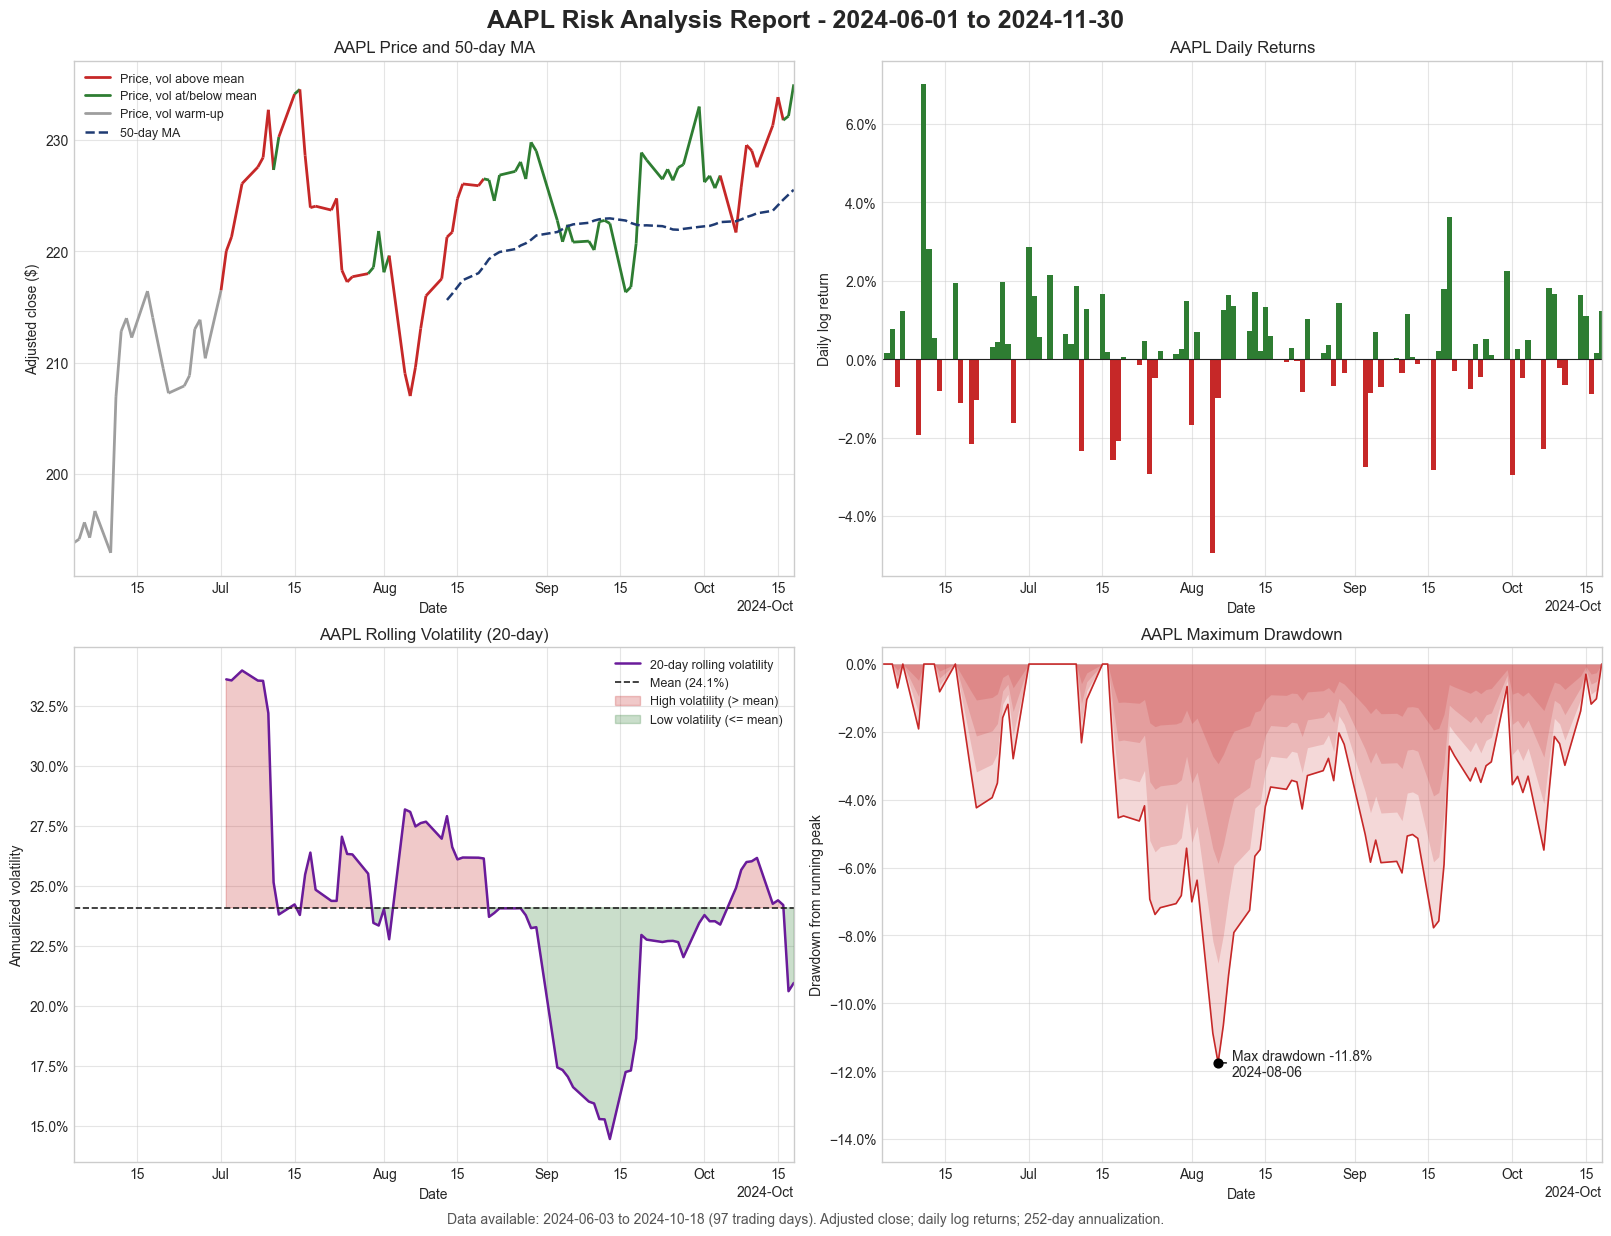

In [9]:
def plot_risk_report(df, ticker, start_date, end_date, mean_volatility):
    """Draw the 2x2 risk report and return the figure."""
    fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout='constrained')
    fig.suptitle(f'{ticker} Risk Analysis Report - {start_date} to {end_date}', fontsize=18, fontweight='bold')
    fig.text(0.5, -0.015, f'Data available: {df.index.min().date()} to {df.index.max().date()} '
             f'({len(df)} trading days). Adjusted close; daily log returns; 252-day annualization.',
             ha='center', fontsize=10, color='#555555')
    x = mdates.date2num(df.index.to_pydatetime())

    # Top left: adjusted price colored by volatility regime, plus the 50-day MA.
    ax = axes[0, 0]
    points = np.column_stack([x, df['adj_close'].to_numpy()])
    segments = np.stack([points[:-1], points[1:]], axis=1)
    vol_end = df['volatility'].to_numpy()[1:]
    seg_colors = np.where(np.isnan(vol_end), COLORS['warmup'],
                          np.where(vol_end > mean_volatility, COLORS['down'], COLORS['up']))
    ax.add_collection(LineCollection(segments, colors=seg_colors, linewidths=2))
    ax.autoscale_view()
    handles = [Line2D([], [], color=COLORS['down'], lw=2, label='Price, vol above mean'),
               Line2D([], [], color=COLORS['up'], lw=2, label='Price, vol at/below mean'),
               Line2D([], [], color=COLORS['warmup'], lw=2, label='Price, vol warm-up')]
    if df['ma_50'].notna().any():
        ax.plot(df.index, df['ma_50'], color=COLORS['ma'], lw=1.8, ls='--', label='50-day MA')
        handles.append(Line2D([], [], color=COLORS['ma'], lw=1.8, ls='--', label='50-day MA'))
    else:
        ax.text(0.02, 0.04, f'50-day MA unavailable: {len(df)} prices (needs {MA_WINDOW})',
                transform=ax.transAxes, fontsize=10, color=COLORS['ma'],
                bbox=dict(facecolor='white', edgecolor=COLORS['ma'], alpha=0.8))
    ax.legend(handles=handles, loc='upper left', fontsize=9, framealpha=0.9)
    ax.set(title=f'{ticker} Price and 50-day MA', ylabel='Adjusted close ($)')

    # Top right: daily log returns.
    ax = axes[0, 1]
    r = df['log_return']
    bar_colors = np.select([r > 0, r < 0], [COLORS['up'], COLORS['down']], COLORS['warmup'])
    ax.bar(df.index, r.fillna(0), color=bar_colors, width=1.0)
    ax.axhline(0, color=COLORS['mean'], lw=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f'{ticker} Daily Returns', ylabel='Daily log return')

    # Bottom left: rolling volatility with regime shading.
    ax = axes[1, 0]
    vol = df['volatility']
    ax.plot(df.index, vol, color=COLORS['vol'], lw=1.8, label=f'{VOL_WINDOW}-day rolling volatility')
    ax.axhline(mean_volatility, color=COLORS['mean'], ls='--', lw=1.2, label=f'Mean ({mean_volatility:.1%})')
    ax.fill_between(df.index, vol, mean_volatility, where=vol > mean_volatility, interpolate=True,
                    color=COLORS['down'], alpha=0.25, label='High volatility (> mean)')
    ax.fill_between(df.index, vol, mean_volatility, where=vol <= mean_volatility, interpolate=True,
                    color=COLORS['up'], alpha=0.25, label='Low volatility (<= mean)')
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(loc='best', fontsize=9)
    ax.set(title=f'{ticker} Rolling Volatility ({VOL_WINDOW}-day)', ylabel='Annualized volatility')

    # Bottom right: drawdown area with a layered red gradient and the maximum marked.
    ax = axes[1, 1]
    dd = df['drawdown']
    for fraction, alpha in [(1.0, 0.18), (0.75, 0.18), (0.5, 0.18), (0.25, 0.18)]:
        ax.fill_between(df.index, dd * fraction, 0, color=COLORS['drawdown'], alpha=alpha, lw=0)
    ax.plot(df.index, dd, color=COLORS['drawdown'], lw=1.2)
    worst = dd.idxmin()
    ax.scatter([worst], [dd.loc[worst]], color='black', zorder=3, s=40)
    ax.annotate(f'Max drawdown {dd.loc[worst]:.1%}\n{worst.date()}', (worst, dd.loc[worst]),
                xytext=(10, -10), textcoords='offset points', fontsize=10,
                arrowprops=dict(arrowstyle='-', color='black'))
    ax.set_ylim(min(dd.min() * 1.25, -0.01), 0.005)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f'{ticker} Maximum Drawdown', ylabel='Drawdown from running peak')

    locator = mdates.AutoDateLocator()
    for ax in axes.flat:
        ax.grid(True, alpha=0.5)
        ax.set_xlabel('Date')
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
        ax.set_xlim(df.index.min(), df.index.max())
    return fig


fig = plot_risk_report(df, ticker, start_date, end_date, mean_volatility)
plt.show()

## 5. Summary statistics

- **Total return** = `last_adj_close / first_adj_close - 1`.
- **Annualized return** = `exp(sum(log_returns) * 252 / n) - 1` for `n` nonmissing returns.
- **Annualized volatility** = `std(log_returns) * sqrt(252)` over the whole period. This is not the same as the *mean rolling volatility* used in the batch summary.
- **Best/worst day** and **average up/down day** use log returns.
- **Positive days** = positive returns ÷ **all** nonmissing returns (zero-return days count in the denominator).
- Undefined values display as `N/A`.

In [10]:
def summary_statistics(df):
    """Report metrics as fractions (NaN when undefined)."""
    r = df['log_return'].dropna()
    up, down = r[r > 0], r[r < 0]
    return {
        'Total Return': df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1,
        'Annualized Return': annualized_return(r),
        'Annualized Volatility': annualized_volatility(r),
        'Sharpe Ratio': calculate_sharpe_ratio(r),
        'Maximum Drawdown': df['drawdown'].min(),
        'Best Day': r.max() if len(r) else np.nan,
        'Worst Day': r.min() if len(r) else np.nan,
        'Positive Days': (r > 0).mean() if len(r) else np.nan,
        'Average Up Day': up.mean() if len(up) else np.nan,
        'Average Down Day': down.mean() if len(down) else np.nan,
    }


def format_metric(name, value):
    """Display formatting only: signed percentages, plain percentages, or a 2-decimal ratio."""
    if pd.isna(value):
        return 'N/A'
    if name == 'Sharpe Ratio':
        return f'{value:.2f}'
    if name in ('Annualized Volatility', 'Positive Days'):
        return f'{value:.2%}'
    return f'{value:+.2%}'


metrics = summary_statistics(df)
summary_table = pd.DataFrame({'Metric': list(metrics), 'Value': [format_metric(k, v) for k, v in metrics.items()]})
print(f'{ticker}: {first_date.date()} to {last_date.date()} ({len(df)} prices, {len(returns)} returns)\n')
print(f'{"Metric":<24}  {"Value":>8}')
print(f'{"-" * 24}  {"-" * 8}')
for row in summary_table.itertuples(index=False):
    print(f'{row.Metric:<24}  {row.Value:>8}')

AAPL: 2024-06-03 to 2024-10-18 (97 prices, 96 returns)

Metric                       Value
------------------------  --------
Total Return               +21.25%
Annualized Return          +65.84%
Annualized Volatility       25.45%
Sharpe Ratio                  1.91
Maximum Drawdown           -11.75%
Best Day                    +7.01%
Worst Day                   -4.94%
Positive Days               62.50%
Average Up Day              +1.09%
Average Down Day            -1.28%


**Reading the report**

- *Total* vs *annualized* return: over a window shorter than a year, annualizing scales the result up, so a short strong run can look extreme. Read the two together.
- A *Sharpe ratio* above about 1 means the excess return was large relative to its volatility over this window. It is a historical description, not a forecast, and a 6–12 month window is a small sample.
- *Maximum drawdown* is the worst peak-to-trough fall in the window. The stock can end with a positive total return and still have had a deep drawdown along the way.
- If the actual observation dates are shorter than the requested window (see Section 2), every metric covers only the available history.

## 6. Results for the batch run

The numbers are saved inside the executed notebook with Scrapbook (`sb.glue`), so `03_run_all_stocks.py` can collect them from each successful report without recalculating anything. Undefined values are stored as `null`.

In [11]:
def json_safe(value):
    """Convert numpy scalars to Python types and NaN to None for JSON storage."""
    if isinstance(value, (np.generic,)):
        value = value.item()
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


report_summary = {
    'ticker': ticker,
    'start_date': start_date,
    'end_date': end_date,
    'first_date': first_date.strftime('%Y-%m-%d'),
    'last_date': last_date.strftime('%Y-%m-%d'),
    'trading_days': len(df),
    'n_returns': len(returns),
    'avg_daily_return': returns.mean(),
    'avg_volatility': mean_volatility,
    'max_drawdown': metrics['Maximum Drawdown'],
    'sharpe_ratio': metrics['Sharpe Ratio'],
    'total_return': metrics['Total Return'],
    'annualized_return': metrics['Annualized Return'],
    'annualized_volatility': metrics['Annualized Volatility'],
    'repaired_rows': int(df['any_repair'].sum()),
}
report_summary = {key: json_safe(value) for key, value in report_summary.items()}
sb.glue('report_summary', report_summary)
print(json.dumps(report_summary, indent=2))

{
  "ticker": "AAPL",
  "start_date": "2024-06-01",
  "end_date": "2024-11-30",
  "first_date": "2024-06-03",
  "last_date": "2024-10-18",
  "trading_days": 97,
  "n_returns": 96,
  "avg_daily_return": 0.002007366837828156,
  "avg_volatility": 0.240840098800071,
  "max_drawdown": -0.11750159880622468,
  "sharpe_ratio": 1.9087206244573933,
  "total_return": 0.21252773334709252,
  "annualized_return": 0.6584052421995119,
  "annualized_volatility": 0.2545456034304724,
  "repaired_rows": 7
}
